In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "qnli"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 104743
    })
    validation: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 5463
    })
    test: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 5463
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['question', 'sentence', 'label', 'idx'],
    num_rows: 104743
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 104743
    })
    validation: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 5463
    })
    test: Dataset({
        features: ['question', 'sentence', 'label', 'idx'],
        num_rows: 5463
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'question': 'When did the third Digimon series begin?',
 'sentence': 'Unlike the two seasons before it and most of the seasons that followed, Digimon Tamers takes a darker and more realistic approach to its story featuring Digimon who do not reincarnate after their deaths and more complex character development in the original Japanese.',
 'label': 1,
 'idx': 0}

In [10]:
raw_train_dataset[5]['question'], raw_train_dataset[5]['sentence']

("When is the term 'German dialects' used in regard to the German language?",
 'When talking about the German language, the term German dialects is only used for the traditional regional varieties.')

In [11]:
raw_train_dataset[5]['label']

0

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'question': Value('string'),
 'sentence': Value('string'),
 'label': ClassLabel(names=['entailment', 'not_entailment']),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["question"], example["sentence"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['question', 'sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 104743
    })
    validation: Dataset({
        features: ['question', 'sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5463
    })
    test: Dataset({
        features: ['question', 'sentence', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5463
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["question", "sentence", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 84]),
 'token_type_ids': torch.Size([32, 84]),
 'attention_mask': torch.Size([32, 84])}

# 4. Load Model

In [19]:
import sys
sys.path.insert(0, '../')

In [20]:
from Bert_model.modeling_bert import BertForSequenceClassification

In [21]:
# id2label, label2id dicts for the outputs for the model
labels = tokenized_datasets["train"].features["labels"].names
num_labels = len(labels)
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = str(i)
    id2label[str(i)] = label

In [22]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [23]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [24]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(0.7970, grad_fn=<NllLossBackward0>) torch.Size([32, 2])


In [25]:
outputs.keys()

odict_keys(['loss', 'logits', 'hidden_states', 'attentions'])

In [26]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)

device

device(type='cuda', index=1)

### Loading Trained Weights

In [27]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [28]:
from train_eval_func import eval_loop

In [29]:
eval_loop(model, val_dataloader, task_name, device)[0]

{'accuracy': 0.9134175361522973}

# 5. Similarity Analysis

In [30]:
from CKA import CKAEvaluator

cka_eval = CKAEvaluator(device)

In [31]:
from CKA import SentenceCKARedundancy

headsCka_eval = SentenceCKARedundancy(device)

In [32]:
def adjacent_similarity_stats(
    similarity_scores, 
    thresold = 0.80,
    disp_sim_score=True, 
    disp_group_count=True
):
    adj_similarities = []
    for i in range(1, len(similarity_scores)):
        adj_similarities.append(similarity_scores[i-1][i])

    if disp_sim_score:
        print("Similarity Scores:", adj_similarities)

    high_pair_count = 0
    for pair in adj_similarities:
        if pair > thresold:
            high_pair_count += 1
    
    if disp_group_count:
        print("Number of High Similar Pairs:", high_pair_count)

    return adj_similarities, high_pair_count

### Using Training Data on CLS Token only

In [33]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:22<00:00,  1.39it/s]

  Reps Similarity Stats:
    Average: 0.878662
    Highest: 0.959961
    Lowest:  0.701227

  Atts Similarity Stats:
    Average: 0.945501
    Highest: 0.995225
    Lowest:  0.752220
  MHA Similarity Stats:
    Average: 0.893494
    Highest: 0.973795
    Lowest:  0.731982
  Pre Wo Similarity Stats:
    Average: 0.787799
    Highest: 0.888987
    Lowest:  0.693147
  Sublayer Similarity Stats:
    Average: 0.930339
    Highest: 0.991154
    Lowest:  0.726501
  Pre Wo Sublayer Similarity Stats:
    Average: 0.817008
    Highest: 0.957663
    Lowest:  0.673449


In [34]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:13<00:00,  1.56it/s]

  Sub Out Similarity Stats:
    Average: 0.854570
    Highest: 0.992332
    Lowest:  0.557542


In [35]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

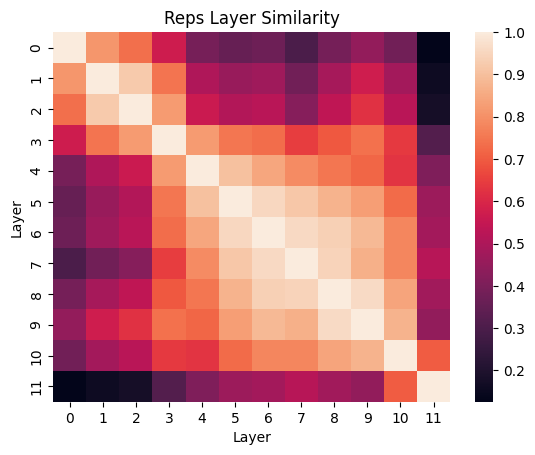

In [36]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [37]:
_,_ = adjacent_similarity_stats(reps_similarity)

Similarity Scores: [0.80925226, 0.9229863, 0.81912184, 0.8214532, 0.90391755, 0.95542026, 0.9584664, 0.9428084, 0.9599605, 0.870669, 0.70122707]
Number of High Similar Pairs: 10


In [38]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.85)

Similarity Scores: [0.80925226, 0.9229863, 0.81912184, 0.8214532, 0.90391755, 0.95542026, 0.9584664, 0.9428084, 0.9599605, 0.870669, 0.70122707]
Number of High Similar Pairs: 7


In [39]:
_,_ = adjacent_similarity_stats(reps_similarity, thresold=0.9)

Similarity Scores: [0.80925226, 0.9229863, 0.81912184, 0.8214532, 0.90391755, 0.95542026, 0.9584664, 0.9428084, 0.9599605, 0.870669, 0.70122707]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

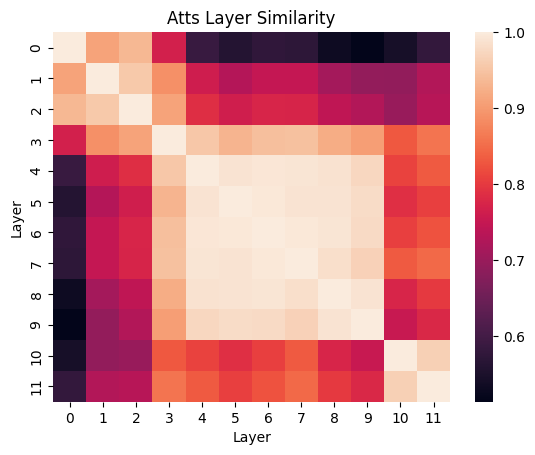

In [40]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [41]:
_,_ = adjacent_similarity_stats(atts_similarity)

Similarity Scores: [0.91053283, 0.9561787, 0.90922755, 0.9532203, 0.9894462, 0.99522513, 0.9943468, 0.9839465, 0.99045706, 0.75221974, 0.965707]
Number of High Similar Pairs: 10


In [42]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.85)

Similarity Scores: [0.91053283, 0.9561787, 0.90922755, 0.9532203, 0.9894462, 0.99522513, 0.9943468, 0.9839465, 0.99045706, 0.75221974, 0.965707]
Number of High Similar Pairs: 10


In [43]:
_,_ = adjacent_similarity_stats(atts_similarity, thresold=0.9)

Similarity Scores: [0.91053283, 0.9561787, 0.90922755, 0.9532203, 0.9894462, 0.99522513, 0.9943468, 0.9839465, 0.99045706, 0.75221974, 0.965707]
Number of High Similar Pairs: 10


Text(50.722222222222214, 0.5, 'Layer')

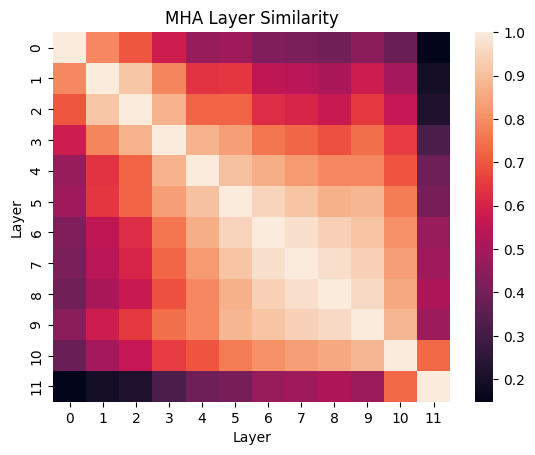

In [44]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [45]:
_,_ = adjacent_similarity_stats(mha_similarity)

Similarity Scores: [0.7891366, 0.9162719, 0.8754899, 0.8752915, 0.9058082, 0.9470735, 0.9737953, 0.97090685, 0.95965403, 0.8830268, 0.73198164]
Number of High Similar Pairs: 9


In [46]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.85)

Similarity Scores: [0.7891366, 0.9162719, 0.8754899, 0.8752915, 0.9058082, 0.9470735, 0.9737953, 0.97090685, 0.95965403, 0.8830268, 0.73198164]
Number of High Similar Pairs: 9


In [47]:
_,_ = adjacent_similarity_stats(mha_similarity, thresold=0.9)

Similarity Scores: [0.7891366, 0.9162719, 0.8754899, 0.8752915, 0.9058082, 0.9470735, 0.9737953, 0.97090685, 0.95965403, 0.8830268, 0.73198164]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

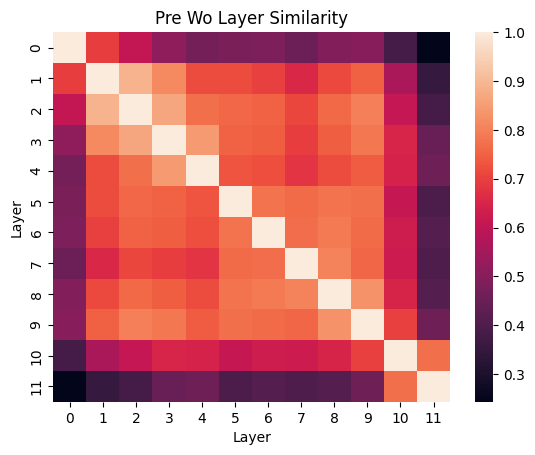

In [48]:
title = "Pre Wo Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [49]:
_,_ = adjacent_similarity_stats(pre_wo_similarity)

Similarity Scores: [0.69314736, 0.8889868, 0.86434036, 0.8435076, 0.73028964, 0.7756568, 0.7675499, 0.80444616, 0.8290547, 0.69858325, 0.77022326]
Number of High Similar Pairs: 5


In [50]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.85)

Similarity Scores: [0.69314736, 0.8889868, 0.86434036, 0.8435076, 0.73028964, 0.7756568, 0.7675499, 0.80444616, 0.8290547, 0.69858325, 0.77022326]
Number of High Similar Pairs: 2


In [51]:
_,_ = adjacent_similarity_stats(pre_wo_similarity, thresold=0.9)

Similarity Scores: [0.69314736, 0.8889868, 0.86434036, 0.8435076, 0.73028964, 0.7756568, 0.7675499, 0.80444616, 0.8290547, 0.69858325, 0.77022326]
Number of High Similar Pairs: 0


Text(50.722222222222214, 0.5, 'Layer')

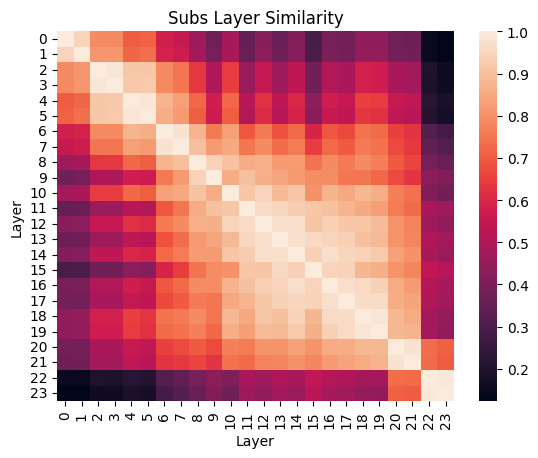

In [52]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [53]:
_,_ = adjacent_similarity_stats(sub_similarity)

Similarity Scores: [0.9481476, 0.8124708, 0.9887303, 0.9207056, 0.98859626, 0.8597448, 0.97863555, 0.89828515, 0.94515955, 0.85786414, 0.91286117, 0.96027297, 0.9716462, 0.9756936, 0.9357393, 0.9476211, 0.9721009, 0.9624931, 0.9840193, 0.8812686, 0.9780833, 0.7265014, 0.99115413]
Number of High Similar Pairs: 22


In [54]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.85)

Similarity Scores: [0.9481476, 0.8124708, 0.9887303, 0.9207056, 0.98859626, 0.8597448, 0.97863555, 0.89828515, 0.94515955, 0.85786414, 0.91286117, 0.96027297, 0.9716462, 0.9756936, 0.9357393, 0.9476211, 0.9721009, 0.9624931, 0.9840193, 0.8812686, 0.9780833, 0.7265014, 0.99115413]
Number of High Similar Pairs: 21


In [55]:
_,_ = adjacent_similarity_stats(sub_similarity, thresold=0.9)

Similarity Scores: [0.9481476, 0.8124708, 0.9887303, 0.9207056, 0.98859626, 0.8597448, 0.97863555, 0.89828515, 0.94515955, 0.85786414, 0.91286117, 0.96027297, 0.9716462, 0.9756936, 0.9357393, 0.9476211, 0.9721009, 0.9624931, 0.9840193, 0.8812686, 0.9780833, 0.7265014, 0.99115413]
Number of High Similar Pairs: 17


Text(50.722222222222214, 0.5, 'Layer')

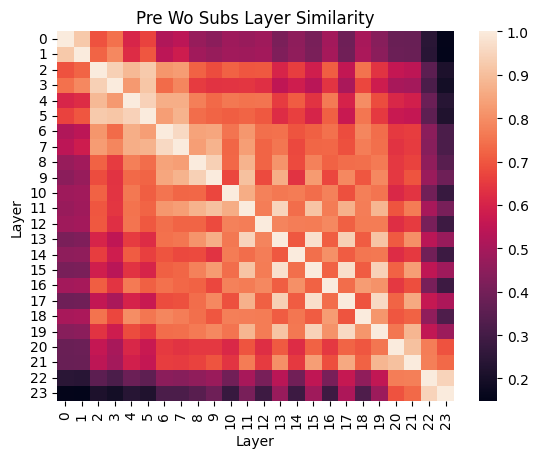

In [56]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [57]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity)

Similarity Scores: [0.9234467, 0.7214077, 0.9378457, 0.82288915, 0.9418173, 0.8335401, 0.95766294, 0.8321316, 0.9395205, 0.6734488, 0.86176455, 0.7688986, 0.7819109, 0.70299125, 0.7431671, 0.71819615, 0.7381633, 0.6966099, 0.81592774, 0.7548644, 0.9060212, 0.7735528, 0.9454008]
Number of High Similar Pairs: 12


In [58]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.9234467, 0.7214077, 0.9378457, 0.82288915, 0.9418173, 0.8335401, 0.95766294, 0.8321316, 0.9395205, 0.6734488, 0.86176455, 0.7688986, 0.7819109, 0.70299125, 0.7431671, 0.71819615, 0.7381633, 0.6966099, 0.81592774, 0.7548644, 0.9060212, 0.7735528, 0.9454008]
Number of High Similar Pairs: 8


In [59]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.9234467, 0.7214077, 0.9378457, 0.82288915, 0.9418173, 0.8335401, 0.95766294, 0.8321316, 0.9395205, 0.6734488, 0.86176455, 0.7688986, 0.7819109, 0.70299125, 0.7431671, 0.71819615, 0.7381633, 0.6966099, 0.81592774, 0.7548644, 0.9060212, 0.7735528, 0.9454008]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

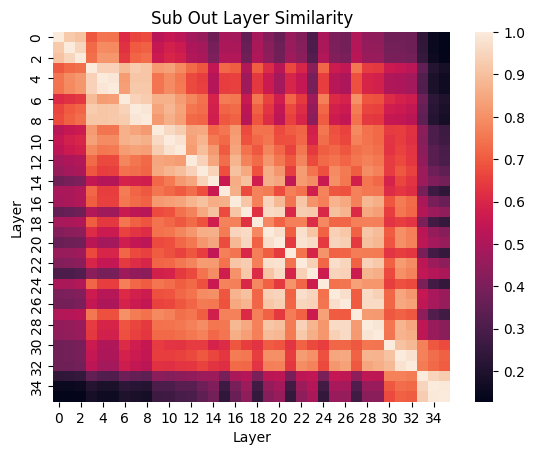

In [60]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [61]:
_,_ = adjacent_similarity_stats(sub_out_similarity)

Similarity Scores: [0.9244585, 0.95136225, 0.735526, 0.94000345, 0.98867714, 0.8265986, 0.94367856, 0.98887426, 0.81694806, 0.95894, 0.97946155, 0.822856, 0.94064677, 0.94329005, 0.5575421, 0.863728, 0.912054, 0.6221003, 0.78523827, 0.97146475, 0.64108044, 0.7427215, 0.9370224, 0.5671449, 0.7397638, 0.97197086, 0.69961846, 0.8203393, 0.9841614, 0.74675786, 0.90765595, 0.9790946, 0.7591056, 0.9477221, 0.9923321]
Number of High Similar Pairs: 24


In [62]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.9234467, 0.7214077, 0.9378457, 0.82288915, 0.9418173, 0.8335401, 0.95766294, 0.8321316, 0.9395205, 0.6734488, 0.86176455, 0.7688986, 0.7819109, 0.70299125, 0.7431671, 0.71819615, 0.7381633, 0.6966099, 0.81592774, 0.7548644, 0.9060212, 0.7735528, 0.9454008]
Number of High Similar Pairs: 8


In [63]:
_,_ = adjacent_similarity_stats(pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.9234467, 0.7214077, 0.9378457, 0.82288915, 0.9418173, 0.8335401, 0.95766294, 0.8321316, 0.9395205, 0.6734488, 0.86176455, 0.7688986, 0.7819109, 0.70299125, 0.7431671, 0.71819615, 0.7381633, 0.6966099, 0.81592774, 0.7548644, 0.9060212, 0.7735528, 0.9454008]
Number of High Similar Pairs: 7


### Using Val Data on CLS Token only

In [64]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_pre_wo_similarity, val_sub_similarity, val_pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_pre_wo_stats = cka_eval.similarity_stats(val_pre_wo_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)
val_pre_wo_subs_stats = cka_eval.similarity_stats(val_pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {val_pre_wo_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {val_pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {val_pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:22<00:00,  1.39it/s]

  Reps Similarity Stats:
    Average: 0.878122
    Highest: 0.960509
    Lowest:  0.690520

  Atts Similarity Stats:
    Average: 0.945487
    Highest: 0.995076
    Lowest:  0.753586
  MHA Similarity Stats:
    Average: 0.893420
    Highest: 0.973198
    Lowest:  0.725410
  Pre Wo Similarity Stats:
    Average: 0.788348
    Highest: 0.890741
    Lowest:  0.684789
  Sublayer Similarity Stats:
    Average: 0.930166
    Highest: 0.988786
    Lowest:  0.724284
  Pre Wo Sublayer Similarity Stats:
    Average: 0.818374
    Highest: 0.958744
    Lowest:  0.667370


In [65]:
val_sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

val_sub_out_stats = cka_eval.similarity_stats(val_sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {val_sub_out_stats['average']:.6f}")
print(f"    Highest: {val_sub_out_stats['max']:.6f}")
print(f"    Lowest:  {val_sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [01:13<00:00,  1.56it/s]

  Sub Out Similarity Stats:
    Average: 0.854330
    Highest: 0.988786
    Lowest:  0.551236


Text(50.722222222222214, 0.5, 'Layer')

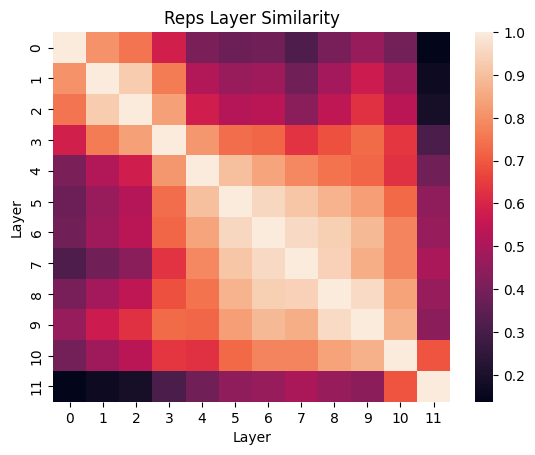

In [66]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [67]:
_,_ = adjacent_similarity_stats(val_reps_similarity)

Similarity Scores: [0.80453914, 0.9288843, 0.8345816, 0.816905, 0.900627, 0.9549807, 0.95650846, 0.941519, 0.9605089, 0.869772, 0.69052005]
Number of High Similar Pairs: 10


In [68]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.85)

Similarity Scores: [0.80453914, 0.9288843, 0.8345816, 0.816905, 0.900627, 0.9549807, 0.95650846, 0.941519, 0.9605089, 0.869772, 0.69052005]
Number of High Similar Pairs: 7


In [69]:
_,_ = adjacent_similarity_stats(val_reps_similarity, thresold=0.9)

Similarity Scores: [0.80453914, 0.9288843, 0.8345816, 0.816905, 0.900627, 0.9549807, 0.95650846, 0.941519, 0.9605089, 0.869772, 0.69052005]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

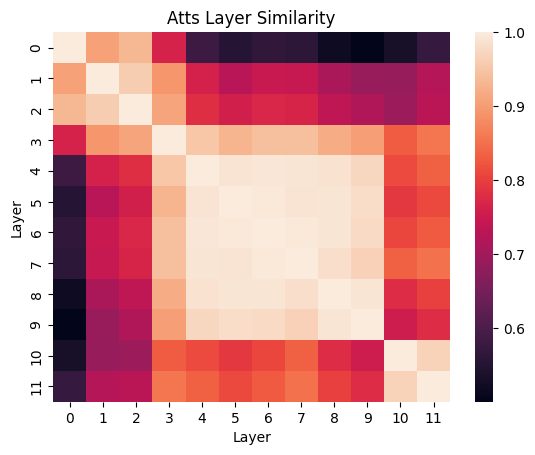

In [70]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [71]:
_,_ = adjacent_similarity_stats(val_atts_similarity)

Similarity Scores: [0.90575963, 0.9593074, 0.9086792, 0.95204675, 0.98878527, 0.9950763, 0.9944266, 0.9841595, 0.9904593, 0.753586, 0.9680732]
Number of High Similar Pairs: 10


In [72]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.85)

Similarity Scores: [0.90575963, 0.9593074, 0.9086792, 0.95204675, 0.98878527, 0.9950763, 0.9944266, 0.9841595, 0.9904593, 0.753586, 0.9680732]
Number of High Similar Pairs: 10


In [73]:
_,_ = adjacent_similarity_stats(val_atts_similarity, thresold=0.9)

Similarity Scores: [0.90575963, 0.9593074, 0.9086792, 0.95204675, 0.98878527, 0.9950763, 0.9944266, 0.9841595, 0.9904593, 0.753586, 0.9680732]
Number of High Similar Pairs: 10


Text(50.722222222222214, 0.5, 'Layer')

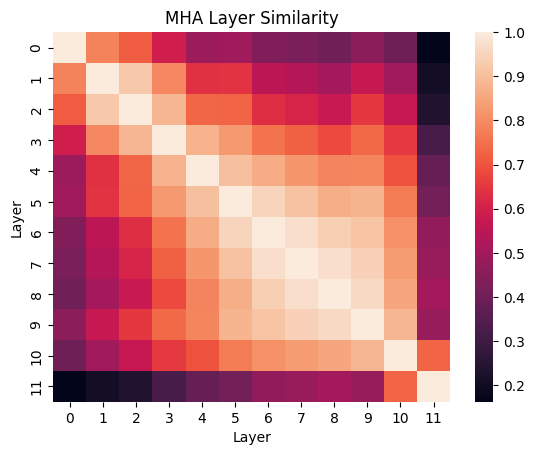

In [74]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [75]:
_,_ = adjacent_similarity_stats(val_mha_similarity)

Similarity Scores: [0.782006, 0.92163944, 0.88387907, 0.8762459, 0.9031611, 0.9478292, 0.97319776, 0.97058725, 0.95980775, 0.8838608, 0.7254103]
Number of High Similar Pairs: 9


In [76]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.85)

Similarity Scores: [0.782006, 0.92163944, 0.88387907, 0.8762459, 0.9031611, 0.9478292, 0.97319776, 0.97058725, 0.95980775, 0.8838608, 0.7254103]
Number of High Similar Pairs: 9


In [77]:
_,_ = adjacent_similarity_stats(val_mha_similarity, thresold=0.9)

Similarity Scores: [0.782006, 0.92163944, 0.88387907, 0.8762459, 0.9031611, 0.9478292, 0.97319776, 0.97058725, 0.95980775, 0.8838608, 0.7254103]
Number of High Similar Pairs: 6


Text(50.722222222222214, 0.5, 'Layer')

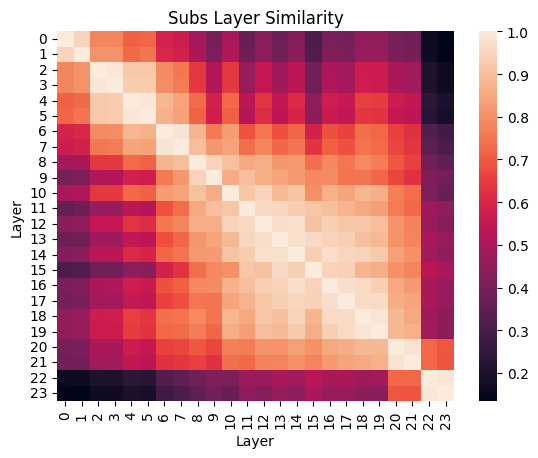

In [78]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [79]:
_,_ = adjacent_similarity_stats(val_sub_similarity)

Similarity Scores: [0.94737613, 0.80551195, 0.98845553, 0.9269236, 0.98872375, 0.86901814, 0.98037374, 0.8959702, 0.94494045, 0.85741, 0.9134082, 0.9587015, 0.97078127, 0.97513604, 0.93352234, 0.9457438, 0.9703365, 0.96297705, 0.9839472, 0.8833157, 0.97816634, 0.7242835, 0.9887858]
Number of High Similar Pairs: 22


In [80]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.85)

Similarity Scores: [0.94737613, 0.80551195, 0.98845553, 0.9269236, 0.98872375, 0.86901814, 0.98037374, 0.8959702, 0.94494045, 0.85741, 0.9134082, 0.9587015, 0.97078127, 0.97513604, 0.93352234, 0.9457438, 0.9703365, 0.96297705, 0.9839472, 0.8833157, 0.97816634, 0.7242835, 0.9887858]
Number of High Similar Pairs: 21


In [81]:
_,_ = adjacent_similarity_stats(val_sub_similarity, thresold=0.9)

Similarity Scores: [0.94737613, 0.80551195, 0.98845553, 0.9269236, 0.98872375, 0.86901814, 0.98037374, 0.8959702, 0.94494045, 0.85741, 0.9134082, 0.9587015, 0.97078127, 0.97513604, 0.93352234, 0.9457438, 0.9703365, 0.96297705, 0.9839472, 0.8833157, 0.97816634, 0.7242835, 0.9887858]
Number of High Similar Pairs: 17


Text(50.722222222222214, 0.5, 'Layer')

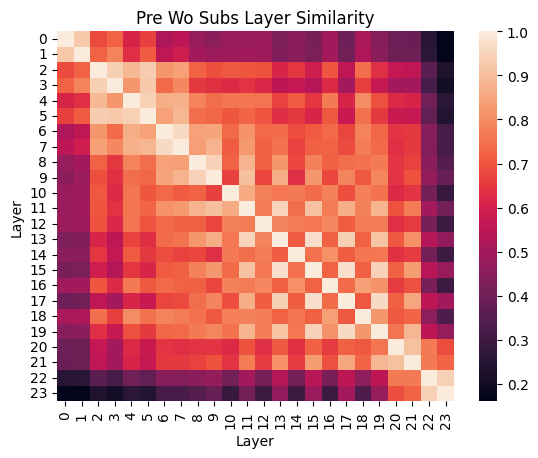

In [82]:
title = "Pre Wo Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_pre_wo_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [83]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity)

Similarity Scores: [0.9230861, 0.72468567, 0.93627834, 0.8193085, 0.9400934, 0.8400791, 0.95874363, 0.83429587, 0.94304305, 0.6673701, 0.86142594, 0.76763076, 0.7848829, 0.7126929, 0.75045484, 0.7236823, 0.74093086, 0.7057831, 0.82126874, 0.7548545, 0.9055505, 0.7660258, 0.9404239]
Number of High Similar Pairs: 12


In [84]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.85)

Similarity Scores: [0.9230861, 0.72468567, 0.93627834, 0.8193085, 0.9400934, 0.8400791, 0.95874363, 0.83429587, 0.94304305, 0.6673701, 0.86142594, 0.76763076, 0.7848829, 0.7126929, 0.75045484, 0.7236823, 0.74093086, 0.7057831, 0.82126874, 0.7548545, 0.9055505, 0.7660258, 0.9404239]
Number of High Similar Pairs: 8


In [85]:
_,_ = adjacent_similarity_stats(val_pre_wo_sub_similarity, thresold=0.9)

Similarity Scores: [0.9230861, 0.72468567, 0.93627834, 0.8193085, 0.9400934, 0.8400791, 0.95874363, 0.83429587, 0.94304305, 0.6673701, 0.86142594, 0.76763076, 0.7848829, 0.7126929, 0.75045484, 0.7236823, 0.74093086, 0.7057831, 0.82126874, 0.7548545, 0.9055505, 0.7660258, 0.9404239]
Number of High Similar Pairs: 7


Text(50.722222222222214, 0.5, 'Layer')

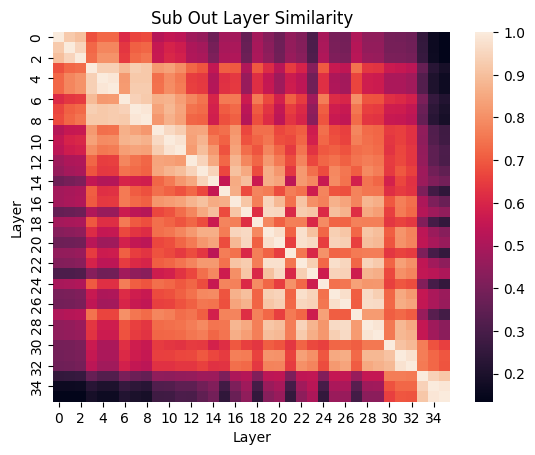

In [86]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [87]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity)

Similarity Scores: [0.9230861, 0.94737613, 0.73405564, 0.93627834, 0.98845553, 0.823722, 0.9400934, 0.98872375, 0.81608605, 0.95874363, 0.98037374, 0.8236032, 0.94304305, 0.94494045, 0.551236, 0.86142594, 0.9134082, 0.6179232, 0.7848829, 0.97078127, 0.6491596, 0.75045484, 0.93352234, 0.5734465, 0.74093086, 0.9703365, 0.70479363, 0.82126874, 0.9839472, 0.75487, 0.9055505, 0.97816634, 0.75766456, 0.9404239, 0.9887858]
Number of High Similar Pairs: 24


In [88]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.85)

Similarity Scores: [0.9230861, 0.94737613, 0.73405564, 0.93627834, 0.98845553, 0.823722, 0.9400934, 0.98872375, 0.81608605, 0.95874363, 0.98037374, 0.8236032, 0.94304305, 0.94494045, 0.551236, 0.86142594, 0.9134082, 0.6179232, 0.7848829, 0.97078127, 0.6491596, 0.75045484, 0.93352234, 0.5734465, 0.74093086, 0.9703365, 0.70479363, 0.82126874, 0.9839472, 0.75487, 0.9055505, 0.97816634, 0.75766456, 0.9404239, 0.9887858]
Number of High Similar Pairs: 20


In [89]:
_,_ = adjacent_similarity_stats(val_sub_out_similarity, thresold=0.9)

Similarity Scores: [0.9230861, 0.94737613, 0.73405564, 0.93627834, 0.98845553, 0.823722, 0.9400934, 0.98872375, 0.81608605, 0.95874363, 0.98037374, 0.8236032, 0.94304305, 0.94494045, 0.551236, 0.86142594, 0.9134082, 0.6179232, 0.7848829, 0.97078127, 0.6491596, 0.75045484, 0.93352234, 0.5734465, 0.74093086, 0.9703365, 0.70479363, 0.82126874, 0.9839472, 0.75487, 0.9055505, 0.97816634, 0.75766456, 0.9404239, 0.9887858]
Number of High Similar Pairs: 19


### Using Training Data using Whole Sequence

In [ ]:
reps_similarity, atts_similarity, mha_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

CKA Sublayer Evaluation:  51%|█████▏    | 59/115 [00:54<01:09,  1.23s/it]

In [ ]:
reps_similarity, atts_similarity, sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

In [ ]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [ ]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Val Data using Whole Sequence

In [49]:
val_reps_similarity, val_atts_similarity, val_mha_similarity, val_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    val_dataloader, 
    device, 
    only_cls_token=False, 
    max_iter=115
)
val_reps_stats = cka_eval.similarity_stats(val_reps_similarity)
val_atts_stats = cka_eval.similarity_stats(val_atts_similarity)
val_mha_stats  = cka_eval.similarity_stats(val_mha_similarity)
val_subs_stats = cka_eval.similarity_stats(val_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {val_reps_stats['average']:.6f}")
print(f"    Highest: {val_reps_stats['max']:.6f}")
print(f"    Lowest:  {val_reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {val_atts_stats['average']:.6f}")
print(f"    Highest: {val_atts_stats['max']:.6f}")
print(f"    Lowest:  {val_atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {val_mha_stats['average']:.6f}")
print(f"    Highest: {val_mha_stats['max']:.6f}")
print(f"    Lowest:  {val_mha_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {val_subs_stats['average']:.6f}")
print(f"    Highest: {val_subs_stats['max']:.6f}")
print(f"    Lowest:  {val_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 13/13 [00:04<00:00,  2.83it/s]

  Reps Similarity Stats:
    Average: 0.991503
    Highest: 0.999282
    Lowest:  0.970845

  Atts Similarity Stats:
    Average: 0.946210
    Highest: 0.991978
    Lowest:  0.770506
  MHA Similarity Stats:
    Average: 0.983591
    Highest: 0.998318
    Lowest:  0.944361
  Sublayer Similarity Stats:
    Average: 0.968635
    Highest: 0.984541
    Lowest:  0.956600


Text(50.722222222222214, 0.5, 'Layer')

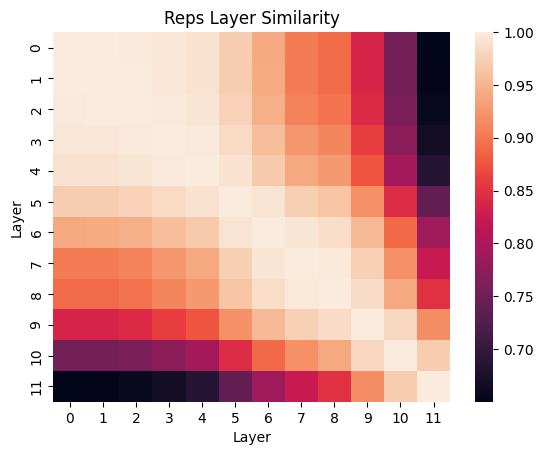

In [50]:
title = "Reps Layer Similarity"
plt.title(title)
sn.heatmap(data = val_reps_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

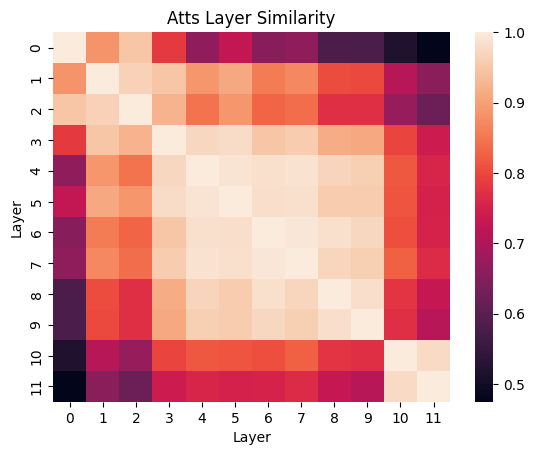

In [51]:
title = "Atts Layer Similarity"
plt.title(title)
sn.heatmap(data = val_atts_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

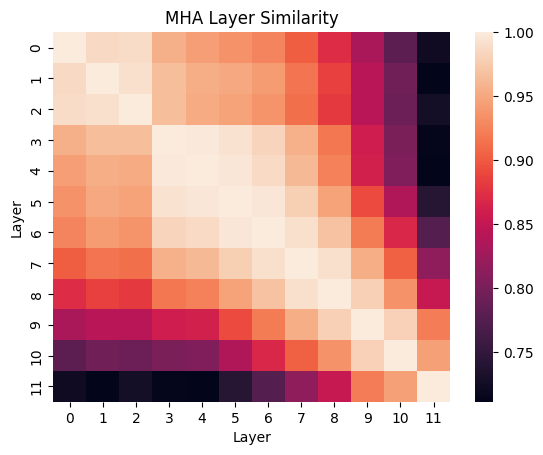

In [52]:
title = "MHA Layer Similarity"
plt.title(title)
sn.heatmap(data = val_mha_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

Text(50.722222222222214, 0.5, 'Layer')

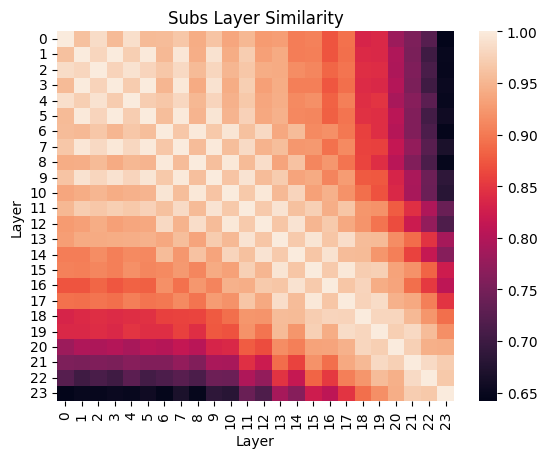

In [53]:
title = "Subs Layer Similarity"
plt.title(title)
sn.heatmap(data = val_sub_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

### Using Training Data for Heads Redundancy

In [ ]:
headsCka_eval

In [47]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 100, 100])

In [46]:
outputs.attentions['attention_head'][11].shape

torch.Size([32, 12, 100, 100])

In [38]:
from CKA import CudaCKA

In [35]:
from tqdm import tqdm

In [54]:
class TestHeadRedundancyEval:
    def __init__(self, device):
        self.cuda_cka = CudaCKA(device)
 
    def collect_selected_layer_head_matrices(self, atts, layer_indices):
        """
        atts: list of length L, each (batch, heads, seq_q, seq_k)
        layer_indices: which layers to include (e.g. [3], [0,1,2], or
                       None for all layers)
 
        Returns:
            matrices: list of (batch, seq_q, seq_k) tensors, UNFLATTENED.
                      Sentence-level CKA needs the (n, n) shape intact --
                      do not flatten these.
            labels: list of (layer_idx, head_idx) tuples, same order/length
                    as matrices. Required to interpret rows/cols of the
                    returned similarity matrix once more than one layer
                    is involved.
        """
        if layer_indices is None:
            layer_indices = [i for i in range(len(atts))]  # fixed: missing ')'
 
        matrices = []
        labels = []
        for layer_idx in layer_indices:
            layer_att = atts[layer_idx]  # (batch, heads, seq_q, seq_k)
            heads = layer_att.shape[1]
            for h in range(heads):
                matrices.append(layer_att[:, h, :, :])
                labels.append((layer_idx, h))
        return matrices, labels
 
    def _accumulate_batch(self, matrices, attention_mask, scores_accum):
        """
        Adds this batch's per-sentence CKA sums into scores_accum (in place)
        and returns how many valid sentences (n_valid >= 2) contributed.
 
        Diagonal entries are CKA(head_i, head_i) for each sentence, which
        is always exactly 1.0 -- so after normalizing by n_valid_sentences
        the diagonal stays exactly 1.0, guaranteed to be the max of every
        row/column. No special-casing needed for "same head = highest
        similarity"; it falls out of CKA's own definition as long as every
        (i, i) pair is computed the same way as every (i, j) pair below.
        """
        M = len(matrices)
        batch = matrices[0].shape[0]
        n_valid_sentences = 0
 
        with torch.no_grad():
            for b in range(batch):
                # Padding-side agnostic: works regardless of left/right padding.
                valid_idx = attention_mask[b].bool()
                n_valid = int(valid_idx.sum().item())
 
                # Guard against degenerate very-short sentences where
                # linear_CKA's variance terms can be ~0 -> NaN.
                if n_valid < 2:
                    continue
                n_valid_sentences += 1
 
                for i in range(M):
                    Ai = matrices[i][b][valid_idx][:, valid_idx]  # (n_valid, n_valid)
                    for j in range(i, M):
                        Bj = matrices[j][b][valid_idx][:, valid_idx]
                        val = self.cuda_cka.linear_CKA(Ai, Bj).detach()
                        scores_accum[i, j] += val
                        if i != j:
                            scores_accum[j, i] += val
                        # i == j case (diagonal): added once, correctly,
                        # via the scores_accum[i, j] += val line above.
 
        return n_valid_sentences
 
    def att_head_redundancy_estimate(self, model, dataloader, device,
                                      max_iter=float("Inf"), layer_indices=None,
                                      attention_mask_key="attention_mask"):
        """
        Runs sentence-level CKA head-redundancy estimation over an entire
        dataloader. Diagonal of the returned matrix is guaranteed to be
        1.0 (a head is always maximally similar to itself), so every
        row/column's max similarity is its own diagonal entry.
 
        Returns:
            scores: (M, M) numpy array, M = len(layer_indices or all)*heads
            labels: list of (layer_idx, head_idx), same order as rows/cols
        """
        model.set_use_module_grafting(False)
        model.set_use_scc_status(False)
 
        n_batch = len(dataloader)
        n_steps = min(n_batch, max_iter) if max_iter != float("Inf") else n_batch
        progress_bar = tqdm(range(n_steps), desc="CKA Sublayer Evaluation")
 
        model.eval()
 
        scores = None
        labels = None
        total_valid_sentences = 0
 
        for step, batch in enumerate(dataloader):
            if step == max_iter:
                break
 
            batch = {k: v.to(device) for k, v in batch.items()}
            attention_mask = batch[attention_mask_key]
 
            with torch.no_grad():
                output = model(**batch)
 
            atts = output.attentions["attention_head"]  # list of (batch, heads, seq_q, seq_k)
 
            matrices, labels = self.collect_selected_layer_head_matrices(atts, layer_indices)
 
            if scores is None:
                M = len(matrices)
                scores = torch.zeros(M, M, device=matrices[0].device)
 
            n_valid = self._accumulate_batch(matrices, attention_mask, scores)
            total_valid_sentences += n_valid
 
            progress_bar.update(1)
 
        if total_valid_sentences == 0:
            scores.fill_(float("nan"))
        else:
            scores = scores / total_valid_sentences
 
        # Sanity: diagonal should be (numerically) 1.0 -- confirms the
        # "same head = highest similarity" property holds by construction.
        return scores.cpu().numpy(), labels

In [55]:
test = TestHeadRedundancyEval(device)

In [57]:
scores, labels = test.att_head_redundancy_estimate(model, train_dataloader, device, layer_indices=[10, 11], max_iter=5)

CKA Sublayer Evaluation: 100%|██████████| 5/5 [00:13<00:00,  2.63s/it]


In [43]:
for batch in train_dataloader:
    batch = {k: v.to(device) for k, v in batch.items()}
    attention_mask = batch['attention_mask']
    with torch.no_grad():
        output = model(**batch)
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 77]),
 'token_type_ids': torch.Size([32, 77]),
 'attention_mask': torch.Size([32, 77])}

In [44]:
len(outputs.attentions['attention_head'])

12

In [45]:
outputs.attentions['attention_head'][0].shape

torch.Size([32, 12, 100, 100])

In [47]:
matrices, labels = test.collect_selected_layer_head_matrices(outputs.attentions['attention_head'], [0, 1])

In [48]:
labels

[(0, 0),
 (0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 11),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (1, 8),
 (1, 9),
 (1, 10),
 (1, 11)]

In [50]:
len(matrices)

24

In [52]:
matrices[0].shape

torch.Size([32, 100, 100])

In [58]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Heads')

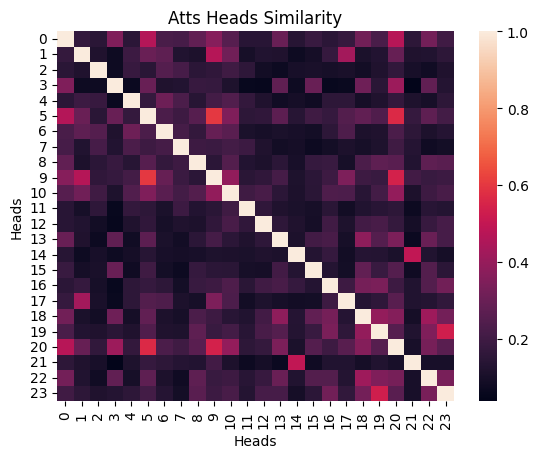

In [59]:
title = "Atts Heads Similarity"
plt.title(title)
sn.heatmap(data = scores)
plt.xlabel("Heads")
plt.ylabel("Heads")

# 6. Sensitivity Score Analysis

In [33]:
from structure_prune_helper import register_importance_masks

In [34]:
register_importance_masks(
    model, device, register_pre_wo_layer=True, register_mha=True, register_mlp=True, register_mha_layer=True, register_mlp_layer=True
)

  Layer 0: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 1: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 2: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 3: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 4: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 5: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 6: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 7: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 8: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 9: Registered (12 heads, 3072 neurons, MHA layer gate, FFN layer gate, pre-WO layer gate)
  Layer 10: Register

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [35]:
from structure_prune_helper import compute_layer_importance_scores

In [36]:
pre_wo_importance, mha_importance, ffn_importance, head_importance, neuron_importance, sublayer_importance =compute_layer_importance_scores(
    model, train_dataloader, device, max_batches=115,
    compute_mha=True, compute_ffn=True, compute_heads=True,
    compute_neurons=True, compute_pre_wo=True,
    display_separate=True, display_combined=True, display_pruning_order=True,
)

Computing importance (pre-WO layer, MHA layer, FFN layer, heads, neurons): 100%|██████████| 115/115 [00:15<00:00,  7.22it/s]


Layer Importance Summary (separate):
          Layer  Pre-WO(layer)     MHA(layer)     FFN(layer)    Heads(mean)  Neurons(mean)
  ------------------------------------------------------------------------------------------
  0                     0.8486         0.8106         0.7784         0.0000         0.0000
  1                     0.5641         0.5621         0.7028         0.0000         0.0000
  2                     0.6781         0.7041         0.6423         0.0000         0.0000
  3                     0.6235         0.6480         0.8485         0.0000         0.0000
  4                     0.8147         0.7851         0.6410         0.0000         0.0000
  5                     0.5328         0.4968         0.5374         0.0000         0.0000
  6                     0.7573         0.7013         0.7554         0.0000         0.0000
  7                     0.7719         0.7588         0.7169         0.0000         0.0000
  8                     0.8044         0.9275     

In [37]:
pre_wo_importance

array([0.8485989 , 0.5641158 , 0.67814785, 0.62345004, 0.81467026,
       0.532822  , 0.7572646 , 0.7719176 , 0.80439585, 0.93461174,
       1.        , 0.5721034 ], dtype=float32)

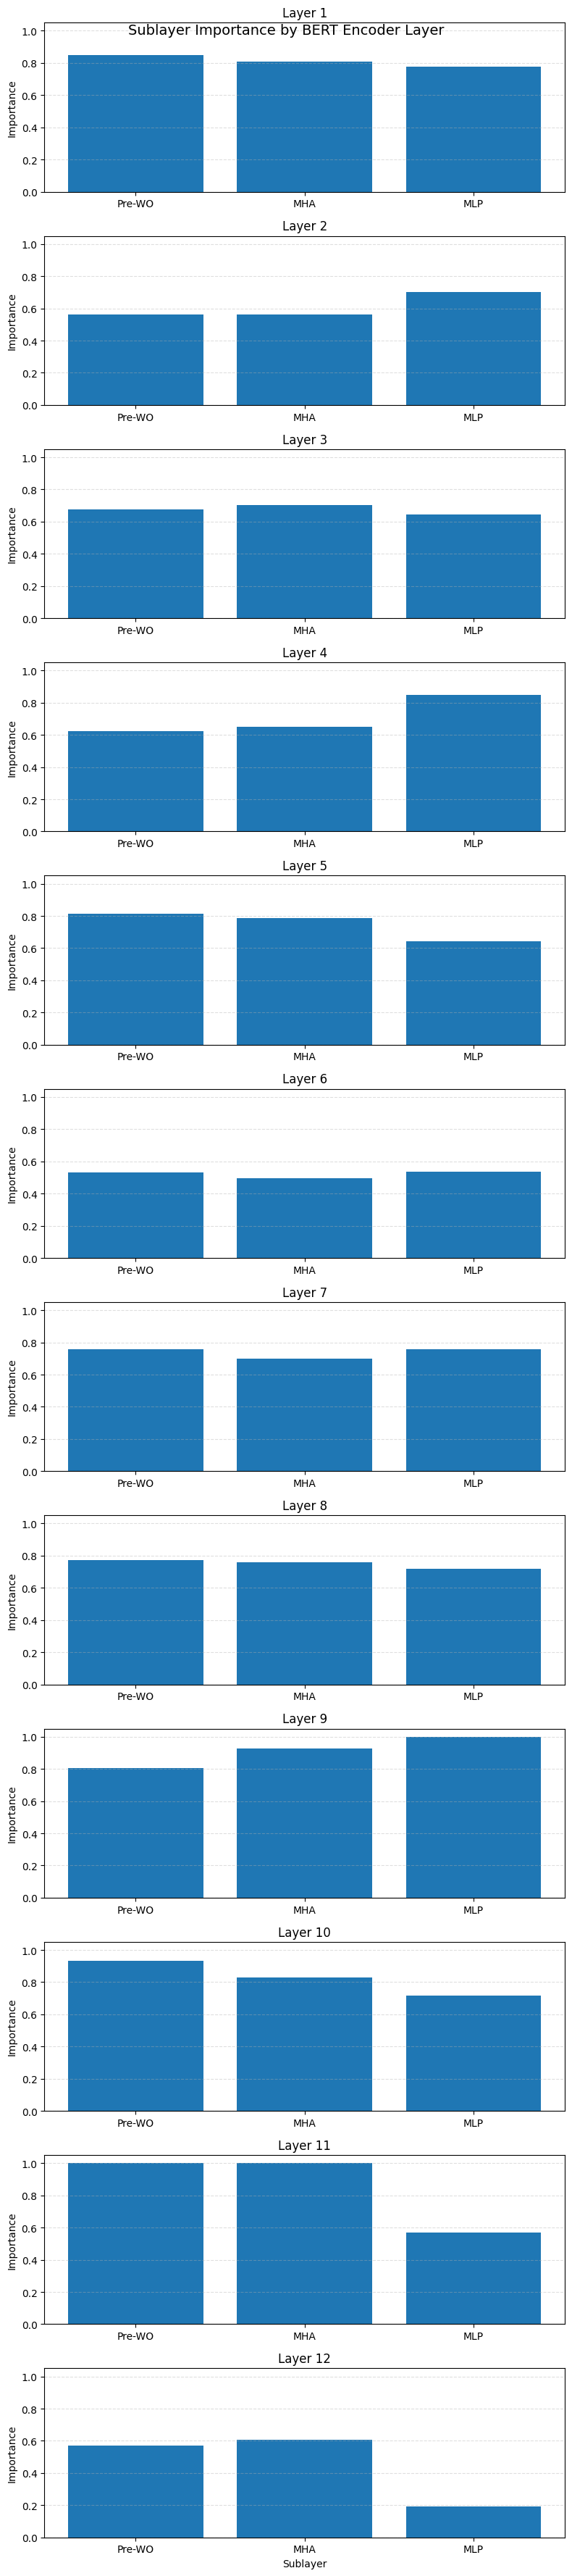

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Importance scores returned by compute_layer_importance_scores()
# pre_wo_importance, mha_importance, ffn_importance

n_layers = len(pre_wo_importance)

fig, axes = plt.subplots(
    n_layers, 1,
    figsize=(8, 3 * n_layers),
    sharey=True
)

# Handle the case of a model with only one layer
if n_layers == 1:
    axes = [axes]

labels = ["Pre-WO", "MHA", "MLP"]

for layer_idx, ax in enumerate(axes):
    scores = [
        pre_wo_importance[layer_idx],
        mha_importance[layer_idx],
        ffn_importance[layer_idx],
    ]

    ax.bar(labels, scores)
    ax.set_title(f"Layer {layer_idx + 1}")
    ax.set_ylabel("Importance")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].set_xlabel("Sublayer")
fig.suptitle("Sublayer Importance by BERT Encoder Layer", fontsize=14)
plt.tight_layout()
plt.show()

### Using Training Data on CLS Token only

In [39]:
reps_similarity, atts_similarity, mha_similarity, pre_wo_similarity, sub_similarity, pre_wo_sub_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115
)
reps_stats = cka_eval.similarity_stats(reps_similarity)
atts_stats = cka_eval.similarity_stats(atts_similarity)
mha_stats = cka_eval.similarity_stats(mha_similarity)
pre_wo_stats = cka_eval.similarity_stats(pre_wo_similarity)
subs_stats = cka_eval.similarity_stats(sub_similarity)
pre_wo_subs_stats = cka_eval.similarity_stats(pre_wo_sub_similarity)

print("  Reps Similarity Stats:")
print(f"    Average: {reps_stats['average']:.6f}")
print(f"    Highest: {reps_stats['max']:.6f}")
print(f"    Lowest:  {reps_stats['min']:.6f}")
print("")

print("  Atts Similarity Stats:")
print(f"    Average: {atts_stats['average']:.6f}")
print(f"    Highest: {atts_stats['max']:.6f}")
print(f"    Lowest:  {atts_stats['min']:.6f}")

print("  MHA Similarity Stats:")
print(f"    Average: {mha_stats['average']:.6f}")
print(f"    Highest: {mha_stats['max']:.6f}")
print(f"    Lowest:  {mha_stats['min']:.6f}")

print("  Pre Wo Similarity Stats:")
print(f"    Average: {pre_wo_stats['average']:.6f}")
print(f"    Highest: {pre_wo_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_stats['min']:.6f}")

print("  Sublayer Similarity Stats:")
print(f"    Average: {subs_stats['average']:.6f}")
print(f"    Highest: {subs_stats['max']:.6f}")
print(f"    Lowest:  {subs_stats['min']:.6f}")

print("  Pre Wo Sublayer Similarity Stats:")
print(f"    Average: {pre_wo_subs_stats['average']:.6f}")
print(f"    Highest: {pre_wo_subs_stats['max']:.6f}")
print(f"    Lowest:  {pre_wo_subs_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:53<00:00,  2.13it/s]

  Reps Similarity Stats:
    Average: 0.877979
    Highest: 0.959605
    Lowest:  0.703123

  Atts Similarity Stats:
    Average: 0.945548
    Highest: 0.995227
    Lowest:  0.747747
  MHA Similarity Stats:
    Average: 0.893045
    Highest: 0.974525
    Lowest:  0.732058
  Pre Wo Similarity Stats:
    Average: 0.788996
    Highest: 0.888900
    Lowest:  0.693331
  Sublayer Similarity Stats:
    Average: 0.930348
    Highest: 0.992332
    Lowest:  0.727088
  Pre Wo Sublayer Similarity Stats:
    Average: 0.818750
    Highest: 0.958940
    Lowest:  0.676651


In [40]:
sub_out_similarity = cka_eval.subLayer_interleaved_pairwise(
    model, 
    train_dataloader, 
    device, 
    only_cls_token=True, 
    max_iter=115,
    do_sub_out=True
)

sub_out_stats = cka_eval.similarity_stats(sub_out_similarity)

print("  Sub Out Similarity Stats:")
print(f"    Average: {sub_out_stats['average']:.6f}")
print(f"    Highest: {sub_out_stats['max']:.6f}")
print(f"    Lowest:  {sub_out_stats['min']:.6f}")

CKA Sublayer Evaluation: 100%|██████████| 115/115 [00:40<00:00,  2.87it/s]

  Sub Out Similarity Stats:
    Average: 0.853961
    Highest: 0.992286
    Lowest:  0.554609


In [41]:
import matplotlib.pyplot as plt
import seaborn as sn

Text(50.722222222222214, 0.5, 'Layer')

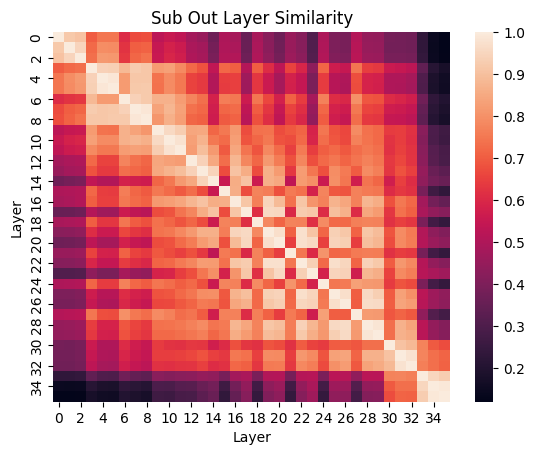

In [42]:
title = "Sub Out Layer Similarity"
plt.title(title)
sn.heatmap(data = sub_out_similarity)
plt.xlabel("Layer")
plt.ylabel("Layer")

In [43]:
sub_out_similarity.shape 

(36, 36)

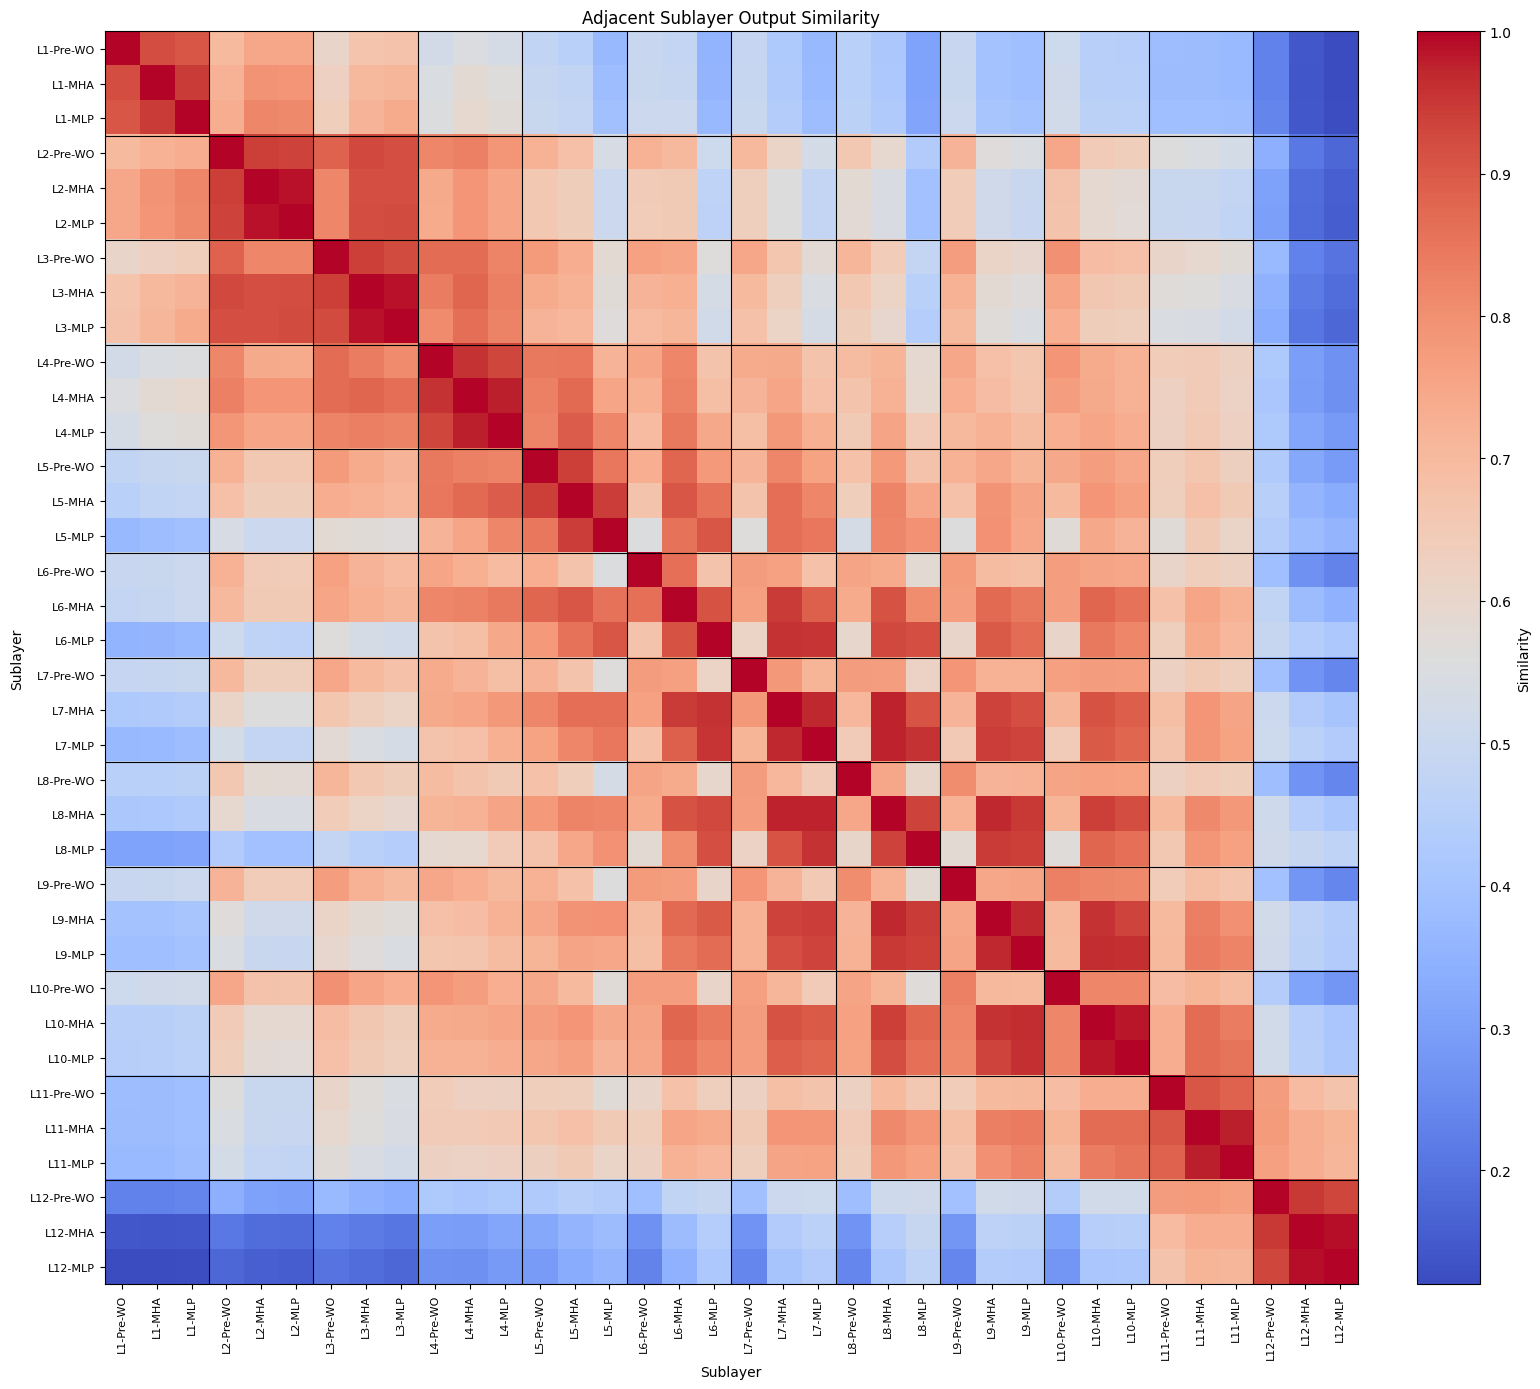

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# sub_out_similarity: (36, 36)
n_layers = 12
sublayers = ["Pre-WO", "MHA", "MLP"]

labels = [
    f"L{layer + 1}-{sub}"
    for layer in range(n_layers)
    for sub in sublayers
]

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    sub_out_similarity,
    cmap="coolwarm",
    interpolation="nearest",
    aspect="equal"
)

# Label every sublayer
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

# Add boundaries between encoder layers
for boundary in range(3, n_layers * 3, 3):
    ax.axhline(boundary - 0.5, color="black", linewidth=0.8)
    ax.axvline(boundary - 0.5, color="black", linewidth=0.8)

# Color scale
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Similarity")

ax.set_title("Adjacent Sublayer Output Similarity")
ax.set_xlabel("Sublayer")
ax.set_ylabel("Sublayer")

plt.tight_layout()
plt.show()